# Supplementary Material S1 — Reproducibility notebook

**Paper:** *The Complexity of Query-Answer Survival under Correlated Data Loss*

This notebook reproduces every empirical result of the paper — data generation, all experiments, Tables 3–9 and Figures 1–2 — and the extended tables of Supplementary Material S2. It runs in Google Colab or any Jupyter environment with Python ≥ 3.10.

**Outputs.** All results are printed and also written to the output folder `OUT`:

| File | Content |
| --- | --- |
| `environment.json` | Python, package versions, CPU, platform, run date |
| `results.json` | All summary statistics |
| `table3_crossing.csv` | Original crossing study (family A, k = 2) |
| `exactness.json` | Section 9.2 |
| `tpch_sf001_per_theta.csv`, `tpch_sf01_per_theta.csv` | Mean survival at all 19 severities (Tables 5, S1, S2) |
| `tpch_sf001_per_nation.csv`, `tpch_sf01_per_nation.csv` | Per-nation results at θ = 0.5 and 0.9 (Tables S3, S4) |
| `q2_sf001_per_theta.csv`, `q2_sf01_per_theta.csv`, `q2_sf1_per_theta.csv` | Second query, all 19 severities (Section 9.5, Table 7, Tables S6a–S6c, S7) |
| `crossing_extended.csv` | Extended crossing study (Table 3, Table S8) |
| `dense_per_theta.csv` | Table 9 and Table S5 |
| `figure1.png`, `figure1.pdf`, `figure2.png`, `figure2.pdf` | Figures 1 and 2 |

**Loss model.** Hybrid loss with common severity θ: every fact and every outage unit is retained independently with probability q = 1 − θ; a fact is present if and only if it and its unit are retained.

**Expected runtime.** About 10 minutes on a two-core machine (566 s in the reported run); the extended crossing study and the SF 1 experiment account for most of it. In all result files, `matched_independence` is the upper bound of Proposition 5 (grouped facts retained independently with probability q²) and `units_ignored` is the unit-free model (every fact retained with probability q).

## 0. Setup

In [1]:
# Install dependencies (run once)
!pip install -q duckdb numpy sympy matplotlib tpchgen-cli

In [2]:
import itertools, math, random, time, json, os, sys, subprocess, platform, datetime
from collections import defaultdict
from fractions import Fraction
import numpy as np, sympy as sp, duckdb, csv

# Output folder: Google Drive when running in Colab (results persist), local folder otherwise.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/answer_survival'
except Exception:
    OUT = os.path.abspath('answer_survival_output')
os.makedirs(OUT, exist_ok=True)
DATA = os.path.join(OUT, 'tpch_data')
print('Results will be written to', OUT)

def write_csv(name, rows):
    with open(os.path.join(OUT, name), 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
RESULTS = {}

Results will be written to /home/claude/final_run2/answer_survival_output


In [3]:
# Record the execution environment
def pkg_version(m):
    try:
        import importlib.metadata as im; return im.version(m)
    except Exception: return 'unknown'
env = dict(run_date_utc=datetime.datetime.utcnow().isoformat(timespec='seconds'),
           python=sys.version.split()[0], platform=platform.platform(), processor=platform.processor(),
           cpu_count=os.cpu_count(),
           packages={p: pkg_version(p) for p in ['duckdb','numpy','sympy','matplotlib','tpchgen-cli']})
try:
    env['cpu_model'] = [l.split(':',1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name')][0]
except Exception: pass
json.dump(env, open(os.path.join(OUT,'environment.json'),'w'), indent=1); print(json.dumps(env, indent=1))

{
 "run_date_utc": "2026-11-07T12:43:30",
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v310-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "cpu_count": 2,
 "packages": {
  "duckdb": "2.0.0",
  "numpy": "2.5.3",
  "sympy": "1.14.0",
  "matplotlib": "3.11.2",
  "tpchgen-cli": "4.0.0"
 },
 "cpu_model": "Intel(R) Xeon(R) Processor @ 2.10GHz"
}


/tmp/ipykernel_2706/3683256621.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  env = dict(run_date_utc=datetime.datetime.utcnow().isoformat(timespec='seconds'),


## 1. Generate TPC-H data (SF 0.01 and 0.1, and the Orders and Lineitem tables at SF 1)
Uses `tpchgen-cli`, an open-source reimplementation of TPC-H dbgen. Results are not official TPC-H results.

In [4]:
for sf, d in [('0.01','sf001'), ('0.1','sf01')]:
    out = os.path.join(DATA, d)
    if not os.path.exists(os.path.join(out, 'partsupp.parquet')):
        subprocess.run(['tpchgen-cli', 'parquet', '-s', sf, f'--output-dir={out}'], check=True)
# SF 1: only the two tables needed by the second query (about 300 MB)
out = os.path.join(DATA, 'sf1')
if not os.path.exists(os.path.join(out, 'lineitem.parquet')):
    subprocess.run(['tpchgen-cli', 'parquet', '-s', '1', '--tables=orders,lineitem', f'--output-dir={out}'], check=True)
con = duckdb.connect()
for d in ['sf001','sf01']:
    print(d, {t: con.execute(f"select count(*) from '{DATA}/{d}/{t}.parquet'").fetchone()[0] for t in ['supplier','partsupp','part']})

sf001 {'supplier': 100, 'partsupp': 8000, 'part': 2000}
sf01 {'supplier': 1000, 'partsupp': 80000, 'part': 20000}


## 2. Core functions (survival model, enumeration, interpolation)

In [5]:
"""Experiments for Paper 1: query-answer survival under hybrid (tuple + group) loss.

Severity model: every base tuple is retained independently with prob q = 1 - theta,
and every group (outage unit) is retained independently with prob q as well
(common-severity hybrid loss). A tuple is present iff it and its group are retained.
"""
import itertools, random, time, math
from fractions import Fraction
from collections import defaultdict

# ---------- generic exact evaluation by enumeration of independent factors ----------

def brute_counts(factors, alive_fn):
    """Return N[k] = number of factor assignments with k alive factors that satisfy alive_fn."""
    n = len(factors)
    N = [0] * (n + 1)
    for bits in itertools.product((0, 1), repeat=n):
        state = dict(zip(factors, bits))
        if alive_fn(state):
            N[sum(bits)] += 1
    return N

def poly_from_counts(N):
    """S(q) = sum_k N_k q^k (1-q)^(n-k), returned as integer coefficients in q (low->high)."""
    n = len(N) - 1
    coeff = [0] * (n + 1)
    for k, Nk in enumerate(N):
        if not Nk:
            continue
        # q^k (1-q)^(n-k) = sum_j C(n-k,j) (-1)^j q^(k+j)
        for j in range(n - k + 1):
            coeff[k + j] += Nk * math.comb(n - k, j) * (-1) ** j
    return coeff

def eval_poly(coeff, q):
    return sum(c * q ** i for i, c in enumerate(coeff))

def interpolate(fn, degree):
    """Exact Lagrange interpolation of a degree<=d polynomial from d+1 rational evaluations.
    Returns integer/Fraction coefficients low->high."""
    xs = [Fraction(i + 1, degree + 2) for i in range(degree + 1)]
    ys = [fn(x) for x in xs]
    coeff = [Fraction(0)] * (degree + 1)
    for i, xi in enumerate(xs):
        # basis polynomial prod_{j!=i} (q - xj)/(xi - xj)
        basis = [Fraction(1)]
        denom = Fraction(1)
        for j, xj in enumerate(xs):
            if j == i:
                continue
            basis = [Fraction(0)] + basis  # multiply by q
            for t in range(len(basis) - 1):
                basis[t] -= xj * basis[t + 1]
            denom *= (xi - xj)
        w = ys[i] / denom
        for t in range(len(basis)):
            coeff[t] += w * basis[t]
    return coeff

# ---------- the running query  Q = exists x,y  R(x), S(x,y)  ----------

def instance(nx, ny, density, rng):
    X = list(range(nx))
    E = [(x, y) for x in X for y in range(ny) if rng.random() < density]
    if not E:
        E = [(0, 0)]
    X = sorted({x for x, _ in E})
    return X, E

def safe_prob_group_on_x(X, E, q):
    """Exact survival when S is grouped on x (Q^G = R(x),S(x,y),G(x): hierarchical)."""
    deg = defaultdict(int)
    for x, _ in E:
        deg[x] += 1
    fail = 1
    for x in X:
        fail *= (1 - q * q * (1 - (1 - q) ** deg[x]))
    return 1 - fail

def factors_group(X, E, on):
    fs = [('R', x) for x in X] + [('S', e) for e in E]
    keys = sorted({(x if on == 'x' else y) for x, y in E})
    fs += [('G', k) for k in keys]
    return fs

def alive_fn(E, on):
    def f(st):
        for x, y in E:
            k = x if on == 'x' else y
            if st[('R', x)] and st[('S', (x, y))] and st[('G', k)]:
                return True
        return False
    return f

def resilience(fs, alive):
    names = list(fs)
    for k in range(len(names) + 1):
        for K in itertools.combinations(names, k):
            st = {f: 1 for f in names}
            for f in K:
                st[f] = 0
            if not alive(st):
                return k
    return len(names)


## 3. Section 9.2 — exactness of the closed form and of interpolation

In [6]:
rng = random.Random(20261106)
n = 0; max_err = 0.0; interp_exact = 0; sizes = []
t0 = time.time()
while n < 200:
    X, E = instance(rng.randint(1,4), rng.randint(1,4), rng.uniform(0.3,0.9), rng)
    fs = factors_group(X, E, 'x')
    if len(fs) > 16: continue
    coeff = poly_from_counts(brute_counts(fs, alive_fn(E,'x')))
    for i in range(1,20):
        q = 1 - i/20
        max_err = max(max_err, abs(eval_poly(coeff,q) - safe_prob_group_on_x(X,E,q)))
    ic = interpolate(lambda q: Fraction(safe_prob_group_on_x(X,E,q)), len(fs))
    interp_exact += all(Fraction(a)==b for a,b in zip(coeff, ic))
    sizes.append(len(fs)); n += 1
ex = dict(instances=n, factors_min=min(sizes), factors_max=max(sizes), max_abs_diff=max_err,
          interpolation_exact=interp_exact, time_s=round(time.time()-t0,1))
RESULTS['exactness'] = ex; json.dump(ex, open(os.path.join(OUT,'exactness.json'),'w'), indent=1); print(ex)

{'instances': 200, 'factors_min': 3, 'factors_max': 16, 'max_abs_diff': 1.432187701766452e-14, 'interpolation_exact': 200, 'time_s': 3.3}


## 4. Section 7.3 / Table 3 — crossing survival curves among equal-resilience answers

In [7]:
q = sp.symbols('q')
def S_poly(degs):
    return sp.expand(1 - sp.Mul(*[1 - q**2*(1-(1-q)**d) for d in degs]))
def crosses(a, b):
    d = sp.Poly(a - b, q)
    if d.is_zero: return False
    _, facs = sp.sqf_list(d)
    n = 0
    for f, m in facs:
        if m % 2 == 0: continue
        n += f.count_roots(0, 1) - (f.eval(0) == 0) - (f.eval(1) == 0)
    return bool(n > 0)
t3 = []
for k in (2, 3):
    ms = list(itertools.combinations_with_replacement(range(1, 7), k))
    P = [S_poly(m) for m in ms]
    pairs = list(itertools.combinations(range(len(ms)), 2))
    cr = sum(crosses(P[i], P[j]) for i, j in pairs)
    t3.append(dict(components_k=k, distinct_answers=len(ms), pairs=len(pairs), crossing_pairs=cr, share_percent=round(100*cr/len(pairs),1)))
d = sp.Poly(S_poly((1,5)) - S_poly((2,3)), q)
cross_theta = [round(1-float(r),3) for r in sp.real_roots(d) if 0 < r < 1]
write_csv('table3_crossing.csv', t3); RESULTS['table3'] = t3; RESULTS['example_crossing_theta'] = cross_theta
for r in t3: print(r)
print('crossing of (1,5) vs (2,3) at theta =', cross_theta)

{'components_k': 2, 'distinct_answers': 21, 'pairs': 210, 'crossing_pairs': 11, 'share_percent': 5.2}
{'components_k': 3, 'distinct_answers': 56, 'pairs': 1540, 'crossing_pairs': 150, 'share_percent': 9.7}
crossing of (1,5) vs (2,3) at theta = [0.748]


## 5. Sections 9.3–9.4 — TPC-H per-nation query
Q(n) ← Supplier(s, n), PartSupp(p, s). Grouping by supplier is tractable; grouping by part is #P-hard.

In [8]:
import duckdb, numpy as np, itertools, time
from collections import defaultdict

THETAS = [round(0.05*i, 2) for i in range(1, 20)]

def load_nations(base):
    con = duckdb.connect()
    sup = con.execute(f"select s_suppkey, s_nationkey from read_parquet('{base}/supplier.parquet', file_row_number=true) order by file_row_number").fetchall()
    ps  = con.execute(f"select ps_partkey, ps_suppkey from read_parquet('{base}/partsupp.parquet', file_row_number=true) order by file_row_number").fetchall()
    nat = defaultdict(list); s2n = {}
    for s, n in sup: nat[n].append(s); s2n[s] = n
    edges = defaultdict(list)
    for p, s in ps: edges[s2n[s]].append((p, s))
    return dict(nat), dict(edges)

def safe_A(nat, edges, n, q):      # PartSupp grouped by supplier: closed form
    deg = defaultdict(int)
    for p, s in edges[n]: deg[s] += 1
    f = 1.0
    for s in nat[n]: f *= 1 - q*q*(1-(1-q)**deg[s])
    return 1 - f

def exact_B(nat, edges, n, q):     # PartSupp grouped by part: exact by conditioning on suppliers
    S = nat[n]; bypart = defaultdict(list)
    for p, s in edges[n]: bypart[p].append(s)
    tot = 0.0
    for bits in itertools.product((0, 1), repeat=len(S)):
        A = {s for s, b in zip(S, bits) if b}
        w = q**len(A) * (1-q)**(len(S)-len(A)); f = 1.0
        for p, ss in bypart.items():
            k = sum(1 for s in ss if s in A)
            if k: f *= 1 - q*(1-(1-q)**k)
        tot += w*(1-f)
    return tot

def upper_B(nat, edges, n, q):     # dissociation upper bound (= independence approximation)
    deg = defaultdict(int)
    for p, s in edges[n]: deg[s] += 1
    f = 1.0
    for s in nat[n]: f *= 1 - q*(1-(1-q*q)**deg[s])
    return 1 - f

def lower_B(nat, edges, n, q):     # symmetric oblivious dissociation lower bound
    kp = defaultdict(int); bys = defaultdict(list)
    for p, s in edges[n]: kp[p] += 1; bys[s].append(p)
    f = 1.0
    for s in nat[n]:
        g = 1.0
        for p in bys[s]: g *= 1 - q*(1-(1-q)**(1.0/kp[p]))
        f *= 1 - q*(1-g)
    return 1 - f

def ignore_units(nat, edges, n, q):   # misspecified tuple-loss model without units
    deg = defaultdict(int)
    for p, s in edges[n]: deg[s] += 1
    f = 1.0
    for s in nat[n]: f *= 1 - q*(1-(1-q)**deg[s])
    return 1 - f

def mc_B(nat, edges, n, q, R, rng):
    S = nat[n]; si = {s: i for i, s in enumerate(S)}
    parts = sorted({p for p, _ in edges[n]}); pi = {p: i for i, p in enumerate(parts)}
    es = np.array([si[s] for p, s in edges[n]]); ep = np.array([pi[p] for p, s in edges[n]])
    a_s = rng.random((R, len(S))) < q; a_e = rng.random((R, len(es))) < q; a_g = rng.random((R, len(parts))) < q
    return (a_s[:, es] & a_e & a_g[:, ep]).any(axis=1).mean()

def run_tpch(base, R, do_exact, seed=7):
    nat, edges = load_nations(base)
    nations = list(nat)  # original insertion order (keeps the Monte Carlo random stream identical to the paper)
    rng = np.random.default_rng(seed)
    out = dict(nations=len(nations),
               suppliers_per_nation=[min(len(nat[n]) for n in nations), max(len(nat[n]) for n in nations)],
               facts_per_nation=[min(len(edges[n]) for n in nations), max(len(edges[n]) for n in nations)], R=R)
    t = time.time(); A = np.array([[safe_A(nat, edges, n, 1-th) for th in THETAS] for n in nations]); out['time_closed_form_s'] = round(time.time()-t, 3)
    t = time.time(); U = np.array([[upper_B(nat, edges, n, 1-th) for th in THETAS] for n in nations]); L = np.array([[lower_B(nat, edges, n, 1-th) for th in THETAS] for n in nations]); out['time_bounds_s'] = round(time.time()-t, 3)
    t = time.time(); M = np.array([[mc_B(nat, edges, n, 1-th, R, rng) for th in THETAS] for n in nations]); out['time_monte_carlo_s'] = round(time.time()-t, 2)
    I = np.array([[ignore_units(nat, edges, n, 1-th) for th in THETAS] for n in nations])
    X = None
    if do_exact:
        t = time.time(); X = np.array([[exact_B(nat, edges, n, 1-th) for th in THETAS] for n in nations]); out['time_exact_s'] = round(time.time()-t, 2)
        out['bounds_valid'] = bool((L <= X + 1e-12).all() and (X <= U + 1e-12).all())
        out['max_abs_err_monte_carlo'] = float(np.abs(M-X).max())
        out['max_err_upper'] = float((U-X).max()); out['max_err_lower'] = float((X-L).max())
        out['max_overestimate_ignore_units'] = float((I-X).max())
    else:
        out['monte_carlo_within_bracket_pm002'] = float(((M >= L-0.02) & (M <= U+0.02)).mean())
    out['mean_bracket_width'] = float((U-L).mean()); out['max_bracket_width'] = float((U-L).max())
    per_theta = []
    for i, th in enumerate(THETAS):
        row = dict(theta=th, lower=L[:, i].mean(), upper=U[:, i].mean(), monte_carlo=M[:, i].mean(),
                   ignore_units=I[:, i].mean(), grouped_by_supplier=A[:, i].mean())
        if X is not None: row['exact'] = X[:, i].mean()
        per_theta.append(row)
    per_nation = []
    for j, n in enumerate(nations):
        row = dict(nation=n, suppliers=len(nat[n]), partsupp_facts=len(edges[n]),
                   parts=len({p for p, _ in edges[n]}),
                   theta_0_5_grouped_by_supplier=A[j, 9], theta_0_5_lower=L[j, 9], theta_0_5_upper=U[j, 9], theta_0_5_mc=M[j, 9],
                   theta_0_9_grouped_by_supplier=A[j, 17], theta_0_9_lower=L[j, 17], theta_0_9_upper=U[j, 17], theta_0_9_mc=M[j, 17])
        if X is not None: row['theta_0_5_exact'] = X[j, 9]; row['theta_0_9_exact'] = X[j, 17]
        per_nation.append(row)
    per_nation.sort(key=lambda r: r["nation"])
    return out, per_theta, per_nation


In [9]:
s001, pt001, pn001 = run_tpch(f'{DATA}/sf001', R=10000, do_exact=True)
write_csv('tpch_sf001_per_theta.csv', pt001); write_csv('tpch_sf001_per_nation.csv', pn001)
RESULTS['tpch_sf001'] = s001; print(json.dumps(s001, indent=1))

{
 "nations": 25,
 "suppliers_per_nation": [
  1,
  8
 ],
 "facts_per_nation": [
  80,
  640
 ],
 "R": 10000,
 "time_closed_form_s": 0.031,
 "time_bounds_s": 0.125,
 "time_monte_carlo_s": 21.77,
 "time_exact_s": 6.11,
 "bounds_valid": true,
 "max_abs_err_monte_carlo": 0.013022133128955282,
 "max_err_upper": 9.302951665568493e-05,
 "max_err_lower": 0.020554518825331436,
 "max_overestimate_ignore_units": 0.2616398684851412,
 "mean_bracket_width": 0.000996521051981798,
 "max_bracket_width": 0.02064754834198712
}


In [10]:
s01, pt01, pn01 = run_tpch(f'{DATA}/sf01', R=1000, do_exact=False)
write_csv('tpch_sf01_per_theta.csv', pt01); write_csv('tpch_sf01_per_nation.csv', pn01)
RESULTS['tpch_sf01'] = s01; print(json.dumps(s01, indent=1))

{
 "nations": 25,
 "suppliers_per_nation": [
  28,
  53
 ],
 "facts_per_nation": [
  2240,
  4240
 ],
 "R": 1000,
 "time_closed_form_s": 0.259,
 "time_bounds_s": 1.382,
 "time_monte_carlo_s": 21.54,
 "monte_carlo_within_bracket_pm002": 0.9894736842105263,
 "mean_bracket_width": 0.0012076920844300027,
 "max_bracket_width": 0.02179413467880842
}


## 6. Section 9.5 — second TPC-H query with an exact baseline at SF 0.01, 0.1 and 1
Q(c) ← Orders(o, c), Lineitem(o, s). Grouping Lineitem by order is tractable; grouping by supplier is #P-hard. Exact values are obtained by conditioning on the supplier units shared by at least two orders of a customer.

In [11]:
# Q(c) <- Orders(o, c), Lineitem(o, s).  Hybrid loss, common severity theta.
# Grouping L: Lineitem grouped by order o  -> tractable (dominance holds)
# Grouping S: Lineitem grouped by supplier s -> #P-hard (dominance fails); exact by conditioning on SHARED units
import duckdb, numpy as np, itertools, time, random
from collections import defaultdict
THETAS = [round(0.05*i, 2) for i in range(1, 20)]

def load(base):
    con = duckdb.connect()
    o = con.execute(f"select o_orderkey, o_custkey from read_parquet('{base}/orders.parquet', file_row_number=true) order by file_row_number").fetchall()
    l = con.execute(f"select l_orderkey, l_suppkey from read_parquet('{base}/lineitem.parquet', file_row_number=true) group by l_orderkey, l_suppkey order by min(file_row_number)").fetchall()
    o2c = dict(o); cust = defaultdict(lambda: defaultdict(list))
    for ok, sk in l: cust[o2c[ok]][ok].append(sk)
    return {c: dict(v) for c, v in cust.items()}

def safe_by_order(orders, q):
    f = 1.0
    for ok, ss in orders.items(): f *= 1 - q*q*(1-(1-q)**len(ss))
    return 1 - f

def shared_units(orders):
    cnt = defaultdict(int)
    for ss in orders.values():
        for s in set(ss): cnt[s] += 1
    return sorted(s for s, k in cnt.items() if k >= 2), cnt

def exact_by_supplier(orders, q, H=None):
    """Exact survival by conditioning on the shared supplier units (vectorised over the 2^|H| states)."""
    if H is None: H, _ = shared_units(orders)
    hi = {s: i for i, s in enumerate(H)}; nH = len(H)
    O = list(orders)
    inc = np.zeros((len(O), nH)); unshared = np.zeros(len(O))
    for j, ok in enumerate(O):
        for s in orders[ok]:
            if s in hi: inc[j, hi[s]] += 1
            else: unshared[j] += 1
    states = ((np.arange(2**nH)[:, None] >> np.arange(nH)) & 1).astype(float) if nH else np.zeros((1, 0))
    k = states.sum(axis=1)
    w = q**k * (1-q)**(nH-k)
    m = states @ inc.T                                  # present shared suppliers per order
    h = (1-q)**m * (1-q*q)**unshared[None, :]           # prob. that no lineitem of the order supports it
    f = np.prod(1 - q*(1-h), axis=1)
    return float(np.dot(w, 1-f))

def matched_independent(orders, q):   # each lineitem retained independently with its true marginal q^2 (= dissociation upper bound)
    f = 1.0
    for ss in orders.values(): f *= 1 - q*(1-(1-q*q)**len(ss))
    return 1 - f

def lower_by_supplier(orders, q):
    _, cnt = shared_units(orders); th = 1-q; f = 1.0
    for ss in orders.values():
        h = 1.0
        for s in ss: h *= 1 - q*(1 - th**(1.0/cnt[s]))
        f *= 1 - q*(1-h)
    return 1 - f

def units_ignored(orders, q):         # unit-free model with per-fact retention q (changes the marginal)
    f = 1.0
    for ss in orders.values(): f *= 1 - q*(1-(1-q)**len(ss))
    return 1 - f

def mc_by_supplier(orders, q, R, rng):
    O = list(orders); sup = sorted({s for ss in orders.values() for s in ss}); si = {s: i for i, s in enumerate(sup)}
    eo = np.array([i for i, ok in enumerate(O) for s in orders[ok]]); es = np.array([si[s] for ok in O for s in orders[ok]])
    ao = rng.random((R, len(O))) < q; ae = rng.random((R, len(eo))) < q; ag = rng.random((R, len(sup))) < q
    return (ao[:, eo] & ae & ag[:, es]).any(axis=1).mean()

def run_q2(base, mc_customers=200, R=10000, seed=7, HMAX=20):
    cust = load(base); allC = sorted(cust)
    C = [c for c in allC if len(shared_units(cust[c])[0]) <= HMAX]
    out = dict(customers_total=len(allC), customers=len(C),
               orders_per_customer=[min(len(cust[c]) for c in C), max(len(cust[c]) for c in C)],
               lineitems_per_customer=[min(sum(len(v) for v in cust[c].values()) for c in C), max(sum(len(v) for v in cust[c].values()) for c in C)],
               shared_units_max=max(len(shared_units(cust[c])[0]) for c in C))
    t = time.time(); A = np.array([[safe_by_order(cust[c], 1-th) for th in THETAS] for c in C]); out['time_closed_form_s'] = round(time.time()-t, 2)
    t = time.time(); U = np.array([[matched_independent(cust[c], 1-th) for th in THETAS] for c in C]); L = np.array([[lower_by_supplier(cust[c], 1-th) for th in THETAS] for c in C]); out['time_bounds_s'] = round(time.time()-t, 2)
    t = time.time(); X = np.array([[exact_by_supplier(cust[c], 1-th) for th in THETAS] for c in C]); out['time_exact_s'] = round(time.time()-t, 2)
    I = np.array([[units_ignored(cust[c], 1-th) for th in THETAS] for c in C])
    rng = np.random.default_rng(seed); sample = random.Random(seed).sample(range(len(C)), min(mc_customers, len(C)))
    t = time.time(); M = np.array([[mc_by_supplier(cust[C[j]], 1-th, R, rng) for th in THETAS] for j in sample]); out['time_mc_s'] = round(time.time()-t, 2); out['mc_customers'] = len(sample); out['R'] = R
    out['bounds_valid'] = bool((L <= X+1e-12).all() and (X <= U+1e-12).all())
    out['max_err_matched_independence'] = float((U-X).max()); out['mean_err_matched_independence'] = float((U-X).mean())
    out['max_err_lower'] = float((X-L).max()); out['max_overestimate_units_ignored'] = float((I-X).max())
    out['max_abs_err_mc'] = float(np.abs(M - X[sample]).max())
    out['mean_bracket_width'] = float((U-L).mean()); out['max_bracket_width'] = float((U-L).max())
    out['per_theta'] = [dict(theta=th, exact=float(X[:, i].mean()), lower=float(L[:, i].mean()), matched_independence=float(U[:, i].mean()),
                             units_ignored=float(I[:, i].mean()), grouped_by_order=float(A[:, i].mean())) for i, th in enumerate(THETAS)]
    return out


In [12]:
Q2 = {}
for d, hmax in [('sf001', 18), ('sf01', 16), ('sf1', 16)]:
    r = run_q2(f'{DATA}/{d}', HMAX=hmax)
    pt = r.pop('per_theta'); write_csv(f'q2_{d}_per_theta.csv', pt); Q2[d] = r
    print(d, json.dumps(r, indent=1))
RESULTS['q2'] = Q2

sf001 {
 "customers_total": 1000,
 "customers": 754,
 "orders_per_customer": [
  2,
  26
 ],
 "lineitems_per_customer": [
  7,
  87
 ],
 "shared_units_max": 18,
 "time_closed_form_s": 0.05,
 "time_bounds_s": 0.48,
 "time_exact_s": 125.43,
 "time_mc_s": 18.61,
 "mc_customers": 200,
 "R": 10000,
 "bounds_valid": true,
 "max_err_matched_independence": 0.007914057974232502,
 "mean_err_matched_independence": 0.0008007277495572056,
 "max_err_lower": 0.13170517354165823,
 "max_overestimate_units_ignored": 0.5453758417451765,
 "max_abs_err_mc": 0.014474469420939107,
 "mean_bracket_width": 0.01610610666440926,
 "max_bracket_width": 0.1390958325198126
}


sf01 {
 "customers_total": 10000,
 "customers": 10000,
 "orders_per_customer": [
  1,
  36
 ],
 "lineitems_per_customer": [
  2,
  155
 ],
 "shared_units_max": 16,
 "time_closed_form_s": 0.64,
 "time_bounds_s": 6.78,
 "time_exact_s": 15.27,
 "time_mc_s": 23.8,
 "mc_customers": 200,
 "R": 10000,
 "bounds_valid": true,
 "max_err_matched_independence": 0.004458823583191274,
 "mean_err_matched_independence": 8.388336334378314e-05,
 "max_err_lower": 0.04460752690869174,
 "max_overestimate_units_ignored": 0.5807911786778781,
 "max_abs_err_mc": 0.014260102403588437,
 "mean_bracket_width": 0.001924639651432882,
 "max_bracket_width": 0.04587369210379655
}


sf1 {
 "customers_total": 99996,
 "customers": 99996,
 "orders_per_customer": [
  1,
  41
 ],
 "lineitems_per_customer": [
  1,
  178
 ],
 "shared_units_max": 5,
 "time_closed_form_s": 6.83,
 "time_bounds_s": 72.9,
 "time_exact_s": 111.45,
 "time_mc_s": 26.01,
 "mc_customers": 200,
 "R": 10000,
 "bounds_valid": true,
 "max_err_matched_independence": 0.0027728646045943606,
 "mean_err_matched_independence": 8.384863546739295e-06,
 "max_err_lower": 0.02296393450641865,
 "max_overestimate_units_ignored": 0.6094518842089327,
 "max_abs_err_mc": 0.014739659537155725,
 "mean_bracket_width": 0.00019297224342728798,
 "max_bracket_width": 0.024068074904913028
}


## 7. Section 7.3 — extended crossing study (two query families)

In [13]:
# Crossing survival curves among equal-resilience answers (exact root counting).
import itertools, random, time
import sympy as sp
q = sp.symbols('q')
def crosses(a, b):
    d = sp.Poly(sp.expand(a - b), q)
    if d.is_zero: return None          # identical curves
    _, facs = sp.sqf_list(d)
    n = 0
    for f, m in facs:
        if m % 2 == 0: continue
        n += f.count_roots(0, 1) - (f.eval(0) == 0) - (f.eval(1) == 0)
    return bool(n > 0)
def comp_A(d):        # family A: R(x), S(x,y), S grouped on x; component = R-fact, unit, d S-facts
    return q**2*(1-(1-q)**d)
def comp_B(de):       # family B: R(x), S(x,y), T(x,z), S grouped on x; component = R-fact, unit, d S-facts, e T-facts
    d, e = de; return q**2*(1-(1-q)**d)*(1-(1-q)**e)
def answer(comp, parts):
    return sp.expand(1 - sp.Mul(*[1 - comp(p) for p in parts]))
def study(comp, types, k, max_pairs=None, seed=1):
    ans = list(itertools.combinations_with_replacement(types, k))
    P = [answer(comp, a) for a in ans]
    pairs = list(itertools.combinations(range(len(ans)), 2))
    if max_pairs and len(pairs) > max_pairs:
        pairs = random.Random(seed).sample(pairs, max_pairs)
    res = [crosses(P[i], P[j]) for i, j in pairs]
    return dict(k=k, answers=len(ans), pairs_tested=len(pairs), sampled=bool(max_pairs and len(pairs) == max_pairs and len(list(itertools.combinations(range(len(ans)),2))) > max_pairs),
                crossing=sum(1 for r in res if r), identical=sum(1 for r in res if r is None))


In [14]:
cross2 = []
for k in (2, 3, 4):
    r = study(comp_A, list(range(1, 11)), k, max_pairs=5000); r['family'] = 'A'; cross2.append(r); print(r)
types = [(d, e) for d in range(1, 5) for e in range(1, 5)]
for k in (2, 3):
    r = study(comp_B, types, k, max_pairs=5000); r['family'] = 'B'; cross2.append(r); print(r)
write_csv('crossing_extended.csv', cross2); RESULTS['crossing_extended'] = cross2

{'k': 2, 'answers': 55, 'pairs_tested': 1485, 'sampled': False, 'crossing': 130, 'identical': 0, 'family': 'A'}


{'k': 3, 'answers': 220, 'pairs_tested': 5000, 'sampled': True, 'crossing': 762, 'identical': 0, 'family': 'A'}


{'k': 4, 'answers': 715, 'pairs_tested': 5000, 'sampled': True, 'crossing': 902, 'identical': 0, 'family': 'A'}


{'k': 2, 'answers': 136, 'pairs_tested': 5000, 'sampled': True, 'crossing': 375, 'identical': 72, 'family': 'B'}


{'k': 3, 'answers': 816, 'pairs_tested': 5000, 'sampled': True, 'crossing': 578, 'identical': 21, 'family': 'B'}


## 8. Section 9.6 / Table 9 — dense sharing (100 synthetic instances, all 19 severities)

In [15]:
import numpy as np, itertools, random
from collections import defaultdict

def run_dense(thetas, n_inst=100, seed=11):
    """Q = R(x),S(x,y) with S grouped on y (#P-hard). Exact by conditioning on the 2^8 states of R."""
    rng = random.Random(seed)
    W = defaultdict(list); EU = defaultdict(list); EL = defaultdict(list); valid = True
    for _ in range(n_inst):
        nx, ny = 8, rng.randint(2, 4)
        E = [(x, y) for x in range(nx) for y in range(ny) if rng.random() < 0.7] or [(0, 0)]
        X = sorted({x for x, _ in E}); byy = defaultdict(list); byx = defaultdict(list)
        for x, y in E: byy[y].append(x); byx[x].append(y)
        for th in thetas:
            q = 1 - th; ex = 0.0
            for bits in itertools.product((0, 1), repeat=len(X)):
                A = {x for x, b in zip(X, bits) if b}; w = q**len(A) * (1-q)**(len(X)-len(A)); f = 1.0
                for y, xs in byy.items():
                    k = sum(1 for x in xs if x in A)
                    if k: f *= 1 - q*(1-(1-q)**k)
                ex += w*(1-f)
            up = 1 - np.prod([1 - q*(1-(1-q*q)**len(byx[x])) for x in X])
            lo = 1 - np.prod([1 - q*(1-np.prod([1 - q*(1-(1-q)**(1/len(byy[y]))) for y in byx[x]])) for x in X])
            valid &= (lo <= ex + 1e-12) and (ex <= up + 2e-12)
            W[th].append(up-lo); EU[th].append(up-ex); EL[th].append(ex-lo)
    rows = [dict(theta=th, mean_width=float(np.mean(W[th])), max_width=float(np.max(W[th])),
                 mean_err_upper=float(np.mean(EU[th])), max_err_upper=float(np.max(EU[th])), mean_err_lower=float(np.mean(EL[th]))) for th in thetas]
    return bool(valid), rows


In [16]:
t0 = time.time()
valid, dense_rows = run_dense([round(0.05*i,2) for i in range(1,20)])
write_csv('dense_per_theta.csv', dense_rows)
RESULTS['dense'] = dict(bounds_valid=valid, time_s=round(time.time()-t0,1))
print('bounds valid:', valid)
for r in dense_rows:
    if r['theta'] in (0.1,0.3,0.5,0.7,0.9): print({k: round(v,4) for k,v in r.items()})

bounds valid: True
{'theta': 0.1, 'mean_width': 0.0112, 'max_width': 0.0355, 'mean_err_upper': 0.0032, 'max_err_upper': 0.0106, 'mean_err_lower': 0.0079}
{'theta': 0.3, 'mean_width': 0.205, 'max_width': 0.3261, 'mean_err_upper': 0.0398, 'max_err_upper': 0.1059, 'mean_err_lower': 0.1652}
{'theta': 0.5, 'mean_width': 0.4667, 'max_width': 0.5788, 'mean_err_upper': 0.0929, 'max_err_upper': 0.1671, 'mean_err_lower': 0.3738}
{'theta': 0.7, 'mean_width': 0.2681, 'max_width': 0.3887, 'mean_err_upper': 0.0389, 'max_err_upper': 0.0566, 'mean_err_lower': 0.2291}
{'theta': 0.9, 'mean_width': 0.0139, 'max_width': 0.0231, 'mean_err_upper': 0.0004, 'max_err_upper': 0.0007, 'mean_err_lower': 0.0136}


## 9. Figures 1 and 2
Figure 1 is computed from the closed-form survival polynomials of Section 7; Figure 2 is drawn from the result files written by Sections 6 and 8 of this notebook.

Figure 1(b): crossing severity theta = 0.7482


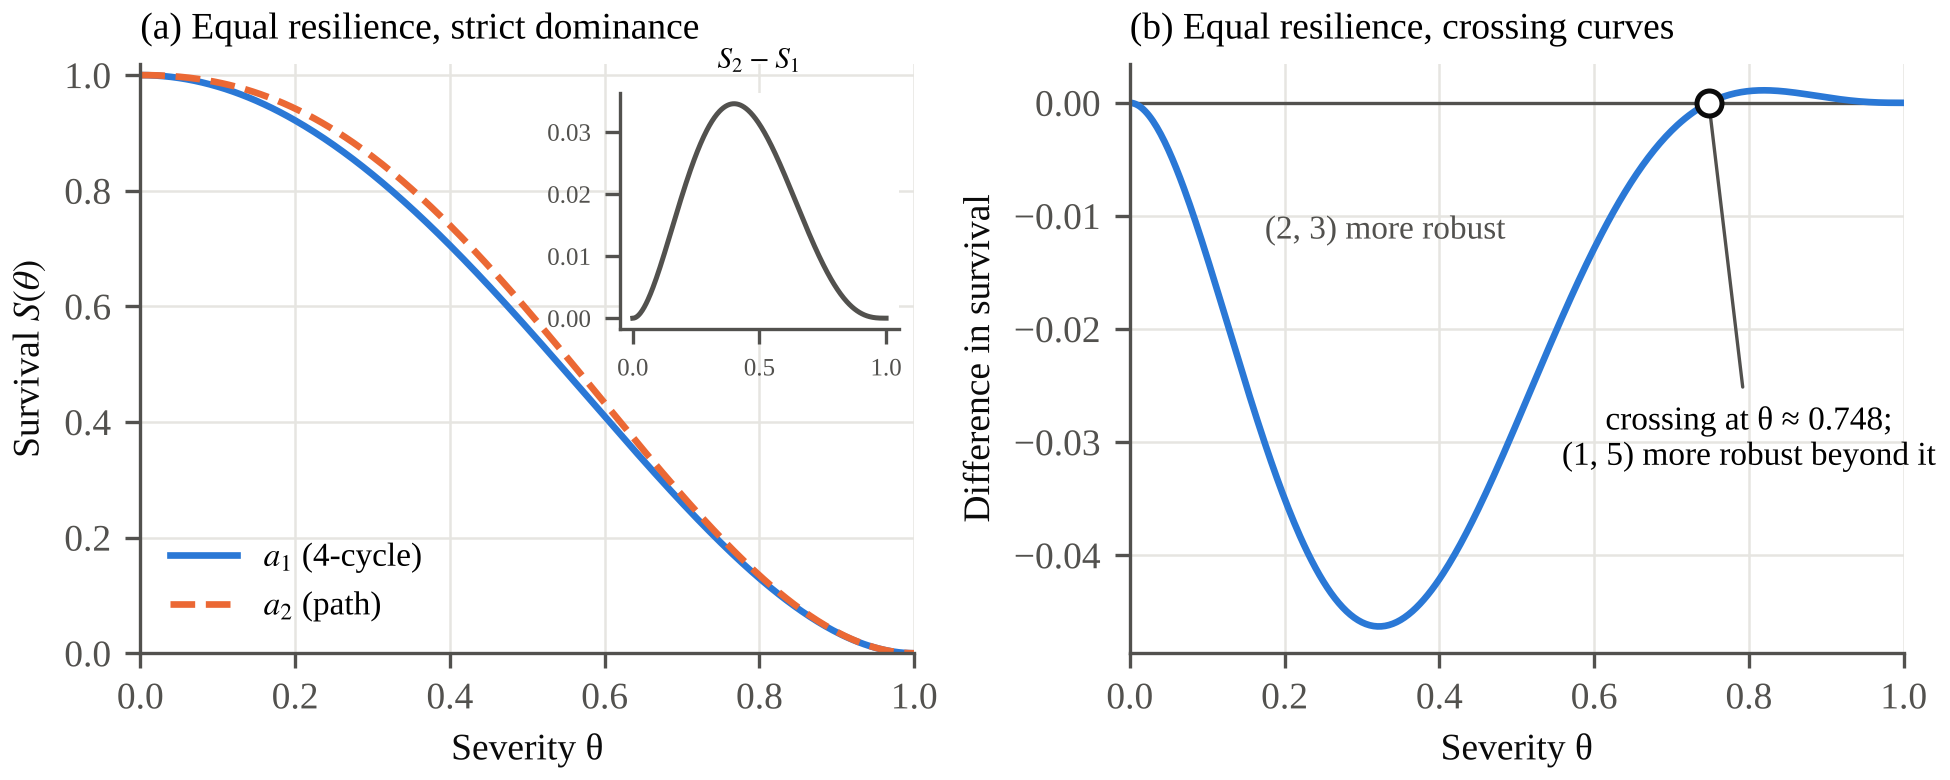

In [17]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','DejaVu Serif'],
    'font.size':9,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#52514e','axes.labelcolor':'#0b0b0b',
    'xtick.color':'#52514e','ytick.color':'#52514e','axes.grid':True,'grid.color':'#e6e5e1','grid.linewidth':0.6,'mathtext.fontset':'stix'})
BLUE, ORANGE, YELLOW, INK, GREY = '#2a78d6', '#eb6834', '#eda100', '#0b0b0b', '#52514e'
th = np.linspace(0, 1, 401); qq = 1 - th

# ---- Figure 1(a): 4-cycle a1 versus path a2 under tuple loss (Section 7.1, equation (14))
S1 = qq**2 * (2 - qq)**2
S2 = qq**2 * (qq**3 - qq**2 - 3*qq + 4)
# ---- Figure 1(b): family-A answers with component sizes (1,5) and (2,3) under hybrid loss (Section 7.3)
def component(d, q): return q**2 * (1 - (1 - q)**d)          # R-fact, unit, at least one of d S-facts
def answer(ds, q):
    p = np.ones_like(q, dtype=float)
    for d in ds: p = p * (1 - component(d, q))
    return 1 - p
diff = lambda t: float(answer([1, 5], np.array([1 - t]))[0] - answer([2, 3], np.array([1 - t]))[0])
lo_, hi_ = 0.5, 0.95                                          # bisection for the crossing severity
for _ in range(80):
    mid = (lo_ + hi_) / 2
    lo_, hi_ = (mid, hi_) if diff(lo_) * diff(mid) > 0 else (lo_, mid)
theta_cross = (lo_ + hi_) / 2
print('Figure 1(b): crossing severity theta =', round(theta_cross, 4))
RESULTS['figure1_crossing_theta'] = theta_cross

fig, ax = plt.subplots(1, 2, figsize=(6.5, 2.6), constrained_layout=True)
a = ax[0]
a.plot(th, S1, color=BLUE, lw=1.6, label='$a_1$ (4-cycle)')
a.plot(th, S2, color=ORANGE, lw=1.6, ls='--', label='$a_2$ (path)')
a.set_xlabel('Severity θ'); a.set_ylabel('Survival $S(θ)$')
a.set_title('(a) Equal resilience, strict dominance', fontsize=9, loc='left')
a.legend(frameon=False, fontsize=8, loc='lower left'); a.set_xlim(0, 1); a.set_ylim(0, 1.02)
ins = a.inset_axes([0.62, 0.55, 0.36, 0.4]); ins.plot(th, S2 - S1, color=GREY, lw=1.2)
ins.set_title('$S_2-S_1$', fontsize=7); ins.tick_params(labelsize=6); ins.grid(False)
a = ax[1]; d15_23 = answer([1, 5], qq) - answer([2, 3], qq)
a.axhline(0, color=GREY, lw=0.8)
a.plot(th, d15_23, color=BLUE, lw=1.6)
a.plot([theta_cross], [0], 'o', ms=6, mfc='white', mec=INK, mew=1.2, zorder=5)
a.annotate(f'crossing at θ ≈ {theta_cross:.3f};\n(1, 5) more robust beyond it', (theta_cross, 0), xytext=(0.8, -0.032),
           fontsize=8, ha='center', arrowprops=dict(arrowstyle='-', color=GREY, lw=0.8))
a.text(0.33, -0.012, '(2, 3) more robust', fontsize=8, color=GREY, ha='center')
a.set_xlabel('Severity θ'); a.set_ylabel('Difference in survival')
a.set_title('(b) Equal resilience, crossing curves', fontsize=9, loc='left'); a.set_xlim(0, 1)
for ext in ('png', 'pdf'): fig.savefig(os.path.join(OUT, f'figure1.{ext}'), dpi=300)
plt.close(fig); display(Image(os.path.join(OUT, 'figure1.png'), width=700))

Figure 2(a): largest gap upper bound - exact = 0.00034749281350032746


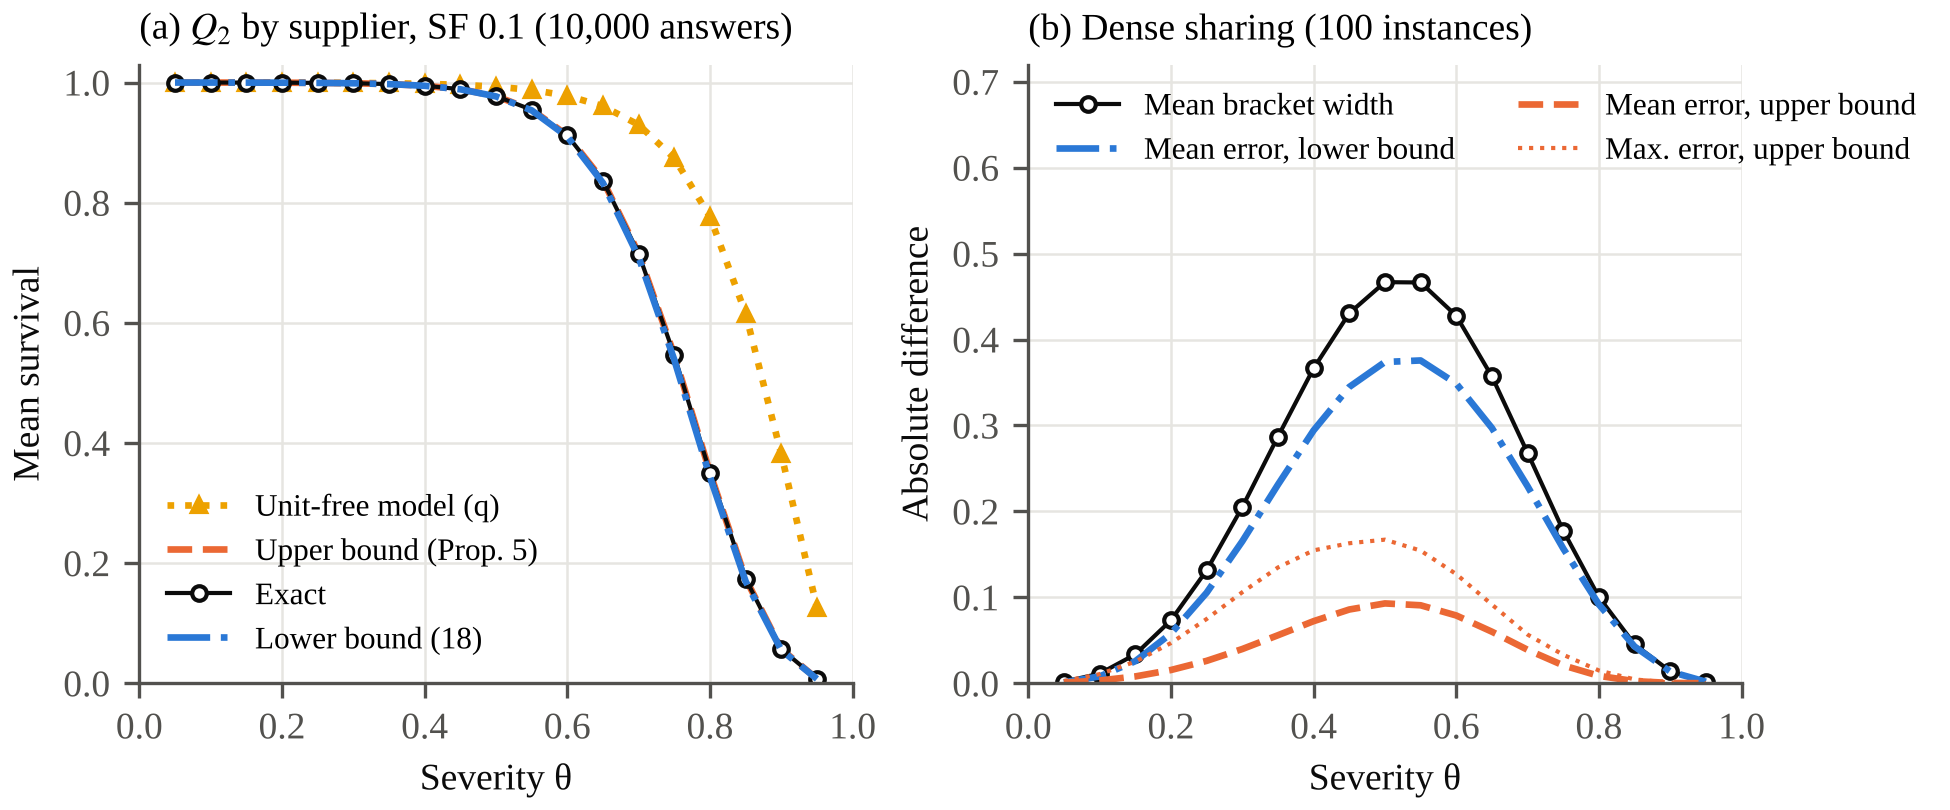

In [18]:
# ---- Figure 2(a): Q2 grouped by supplier, SF 0.1, all 19 severities (from Section 6)
rows = list(csv.DictReader(open(os.path.join(OUT, 'q2_sf01_per_theta.csv'))))
col = lambda k: np.array([float(r[k]) for r in rows])
t2, ex, lo, up, uf = col('theta'), col('exact'), col('lower'), col('matched_independence'), col('units_ignored')
# ---- Figure 2(b): dense sharing, all 19 severities (from Section 8)
dr = list(csv.DictReader(open(os.path.join(OUT, 'dense_per_theta.csv'))))
dcol = lambda k: np.array([float(r[k]) for r in dr])
print('Figure 2(a): largest gap upper bound - exact =', float((up - ex).max()))

fig, ax = plt.subplots(1, 2, figsize=(6.5, 2.7), constrained_layout=True)
a = ax[0]
a.plot(t2, uf, color=YELLOW, lw=1.6, ls=':', marker='^', ms=3.5, label='Unit-free model (q)')
a.plot(t2, up, color=ORANGE, lw=1.6, ls='--', label='Upper bound (Prop. 5)')
a.plot(t2, ex, color=INK, lw=1.0, marker='o', ms=3.5, mfc='white', label='Exact')
a.plot(t2, lo, color=BLUE, lw=1.6, ls='-.', label='Lower bound (18)')
a.set_xlabel('Severity θ'); a.set_ylabel('Mean survival')
a.set_title('(a) $Q_2$ by supplier, SF 0.1 (10,000 answers)', fontsize=9, loc='left')
a.legend(frameon=False, fontsize=7.5, loc='lower left'); a.set_xlim(0, 1); a.set_ylim(0, 1.03)
a = ax[1]; td = dcol('theta')
a.plot(td, dcol('mean_width'), color=INK, lw=1.0, marker='o', ms=3.5, mfc='white', label='Mean bracket width')
a.plot(td, dcol('mean_err_lower'), color=BLUE, lw=1.6, ls='-.', label='Mean error, lower bound')
a.plot(td, dcol('mean_err_upper'), color=ORANGE, lw=1.6, ls='--', label='Mean error, upper bound')
a.plot(td, dcol('max_err_upper'), color=ORANGE, lw=1.0, ls=':', label='Max. error, upper bound')
a.set_xlabel('Severity θ'); a.set_ylabel('Absolute difference')
a.set_title('(b) Dense sharing (100 instances)', fontsize=9, loc='left')
a.legend(frameon=False, fontsize=7.5, loc='upper left', ncol=2); a.set_xlim(0, 1); a.set_ylim(0, 0.72)
for ext in ('png', 'pdf'): fig.savefig(os.path.join(OUT, f'figure2.{ext}'), dpi=300)
plt.close(fig); display(Image(os.path.join(OUT, 'figure2.png'), width=700))

## 10. Save all results

In [19]:
json.dump(RESULTS, open(os.path.join(OUT,'results.json'),'w'), indent=1, default=float)
print('Saved:', sorted(os.listdir(OUT)))

Saved: ['crossing_extended.csv', 'dense_per_theta.csv', 'environment.json', 'exactness.json', 'figure1.pdf', 'figure1.png', 'figure2.pdf', 'figure2.png', 'q2_sf001_per_theta.csv', 'q2_sf01_per_theta.csv', 'q2_sf1_per_theta.csv', 'results.json', 'table3_crossing.csv', 'tpch_data', 'tpch_sf001_per_nation.csv', 'tpch_sf001_per_theta.csv', 'tpch_sf01_per_nation.csv', 'tpch_sf01_per_theta.csv']


## 11. Where each result of the paper comes from

| Paper item | Notebook section | Output file(s) | Ground truth |
| --- | --- | --- | --- |
| Section 9.2 | 3 | `exactness.json` | exact (brute force) |
| Table 3, Table S8 | 7 (family A, k = 2 also in 4) | `crossing_extended.csv`, `table3_crossing.csv` | exact arithmetic |
| Tables 4 and 5, Tables S1 and S3 | 5 | `results.json` (`tpch_sf001`), `tpch_sf001_*.csv` | exact |
| Table 6 | 5 | `results.json` (time fields) | running time |
| Section 9.4, Tables S2 and S4 | 5 | `results.json` (`tpch_sf01`), `tpch_sf01_*.csv` | consistency only |
| Tables 7 and 8, Tables S6–S7 | 6 | `results.json` (`q2`), `q2_*_per_theta.csv` | exact for evaluated customers |
| Table 9, Table S5 | 8 | `dense_per_theta.csv` | exact |
| Figure 1 | 9 | `figure1.png`, `figure1.pdf` | closed form |
| Figure 2 | 9 | `figure2.png`, `figure2.pdf` | from Sections 6 and 8 |